In [1]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

In [2]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_DIR = current_dir.parent
else:
    PROJECT_DIR = current_dir

DATA_DIR = PROJECT_DIR / "data"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

VAE_CONFIG = CONFIG["models"]["vae"]

SEED = CONFIG["general"]["random_seed"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", CONFIG["general"]["project_name"])
print("Dataset:", CONFIG["general"]["dataset"])
print("Device:", device)
print("Latent Dimension:", VAE_CONFIG["latent_dim"])
print("Batch Size:", CONFIG["general"]["batch_size"])

Project: Generative Models Comparison
Dataset: Fashion-MNIST
Device: cpu
Latent Dimension: 64
Batch Size: 128


In [5]:
dataset_path = DATA_DIR / "fashion_mnist" / "fashion_mnist_splits.pt"

dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=False
)

X_train = dataset["train_images"]
X_val = dataset["val_images"]
X_test = dataset["test_images"]

y_train = dataset["train_labels"]
y_val = dataset["val_labels"]
y_test = dataset["test_labels"]

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)
print("Testing Images:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Validation Labels:", y_val.shape)
print("Testing Labels:", y_test.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])

Training Labels: torch.Size([56000])
Validation Labels: torch.Size([7000])
Testing Labels: torch.Size([7000])


In [6]:
# Normalize Images
X_train = X_train.float() / 255.0
X_val = X_val.float() / 255.0
X_test = X_test.float() / 255.0

# Flatten Images
X_train = X_train.view(-1, 784)
X_val = X_val.view(-1, 784)
X_test = X_test.view(-1, 784)

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nPixel Value Range:")
print("Minimum:", X_train.min().item())
print("Maximum:", X_train.max().item())

Training Shape: torch.Size([56000, 784])
Validation Shape: torch.Size([7000, 784])
Testing Shape: torch.Size([7000, 784])

Pixel Value Range:
Minimum: 0.0
Maximum: 1.0


In [7]:
train_dataset = TensorDataset(X_train, X_train)
val_dataset = TensorDataset(X_val, X_val)
test_dataset = TensorDataset(X_test, X_test)

BATCH_SIZE = CONFIG["general"]["batch_size"]

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))
print("Batch Size:", BATCH_SIZE)

Training Batches: 438
Validation Batches: 55
Testing Batches: 55
Batch Size: 128


In [8]:
class VariationalAutoencoder(nn.Module):
    def __init__(self, config):
        super(VariationalAutoencoder, self).__init__()

        # Encoder
        encoder_layers = []
        encoder_dims = config["encoder"]

        for i in range(len(encoder_dims) - 1):
            encoder_layers.append(
                nn.Linear(encoder_dims[i], encoder_dims[i + 1])
            )
            encoder_layers.append(nn.ReLU())

        self.encoder = nn.Sequential(*encoder_layers)

        # Latent Distribution
        self.fc_mu = nn.Linear(
            encoder_dims[-1],
            config["latent_dim"]
        )

        self.fc_logvar = nn.Linear(
            encoder_dims[-1],
            config["latent_dim"]
        )

        # Decoder
        decoder_layers = []
        decoder_dims = config["decoder"]

        for i in range(len(decoder_dims) - 1):
            decoder_layers.append(
                nn.Linear(decoder_dims[i], decoder_dims[i + 1])
            )

            if i < len(decoder_dims) - 2:
                decoder_layers.append(nn.ReLU())
            else:
                decoder_layers.append(nn.Sigmoid())

        self.decoder = nn.Sequential(*decoder_layers)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)

        return mu + epsilon * std

    def forward(self, x):
        encoded = self.encoder(x)

        mu = self.fc_mu(encoded)
        logvar = self.fc_logvar(encoded)

        latent = self.reparameterize(mu, logvar)

        reconstructed = self.decoder(latent)

        return reconstructed, mu, logvar

In [9]:
model = VariationalAutoencoder(VAE_CONFIG).to(device)

print(model)

VariationalAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


In [10]:
# Loss Configuration
criterion = nn.MSELoss(reduction="sum")

KL_WEIGHT = VAE_CONFIG["kl_weight"]

# Optimizer
LEARNING_RATE = VAE_CONFIG["learning_rate"]

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

EPOCHS = VAE_CONFIG["epochs"]

print("KL Weight:", KL_WEIGHT)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)

KL Weight: 1.0
Learning Rate: 0.001
Epochs: 50


In [11]:
def vae_loss_function(reconstructed, original, mu, logvar):
    # Reconstruction Loss
    reconstruction_loss = criterion(reconstructed, original)

    # KL Divergence Loss
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    # Total Loss
    total_loss = reconstruction_loss + KL_WEIGHT * kl_loss

    return total_loss, reconstruction_loss, kl_loss

In [12]:
train_losses = []
val_losses = []

train_reconstruction_losses = []
train_kl_losses = []

best_val_loss = float("inf")

checkpoint_path = CHECKPOINTS_DIR / "vae.pth"

# Training 
for epoch in range(EPOCHS):

    model.train()

    train_total = 0.0
    train_recon = 0.0
    train_kl = 0.0

    for images, _ in train_loader:
        images = images.to(device)

        optimizer.zero_grad()

        reconstructed, mu, logvar = model(images)

        total_loss, recon_loss, kl_loss = vae_loss_function(
            reconstructed, images, mu, logvar
        )

        loss = total_loss / images.size(0)
        loss.backward()

        optimizer.step()

        train_total += total_loss.item()
        train_recon += recon_loss.item()
        train_kl += kl_loss.item()

    # Average Training Loss
    train_total /= len(train_dataset)
    train_recon /= len(train_dataset)
    train_kl /= len(train_dataset)

    train_losses.append(train_total)
    train_reconstruction_losses.append(train_recon)
    train_kl_losses.append(train_kl)

    # Validation
    model.eval()

    val_total = 0.0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)

            reconstructed, mu, logvar = model(images)

            total_loss, _, _ = vae_loss_function(
                reconstructed, images, mu, logvar
            )

            val_total += total_loss.item()

    val_total /= len(val_dataset)
    val_losses.append(val_total)

    # Save Best Checkpoint
    if val_total < best_val_loss:
        best_val_loss = val_total

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": best_val_loss
        }, checkpoint_path)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_total:.6f} "
        f"Val Loss: {val_total:.6f} "
        f"Recon Loss: {train_recon:.6f} "
        f"KL Loss: {train_kl:.6f}"
    )

print("\nTraining Completed!")
print(f"Best Validation Loss: {best_val_loss:.6f}")

Epoch [1/50] Train Loss: 44.964853 Val Loss: 34.464339 Recon Loss: 39.621172 KL Loss: 5.343681
Epoch [2/50] Train Loss: 30.482500 Val Loss: 28.504563 Recon Loss: 24.167675 KL Loss: 6.314825
Epoch [3/50] Train Loss: 27.574579 Val Loss: 26.973184 Recon Loss: 21.268747 KL Loss: 6.305832
Epoch [4/50] Train Loss: 26.372034 Val Loss: 25.827819 Recon Loss: 19.906818 KL Loss: 6.465216
Epoch [5/50] Train Loss: 25.657693 Val Loss: 25.548865 Recon Loss: 19.068161 KL Loss: 6.589532
Epoch [6/50] Train Loss: 25.270332 Val Loss: 25.237312 Recon Loss: 18.587568 KL Loss: 6.682764
Epoch [7/50] Train Loss: 25.056474 Val Loss: 25.041559 Recon Loss: 18.290148 KL Loss: 6.766326
Epoch [8/50] Train Loss: 24.814741 Val Loss: 24.884893 Recon Loss: 17.975042 KL Loss: 6.839699
Epoch [9/50] Train Loss: 24.588549 Val Loss: 24.605678 Recon Loss: 17.675492 KL Loss: 6.913056
Epoch [10/50] Train Loss: 24.424855 Val Loss: 24.631024 Recon Loss: 17.439590 KL Loss: 6.985266
Epoch [11/50] Train Loss: 24.306629 Val Loss: 24.

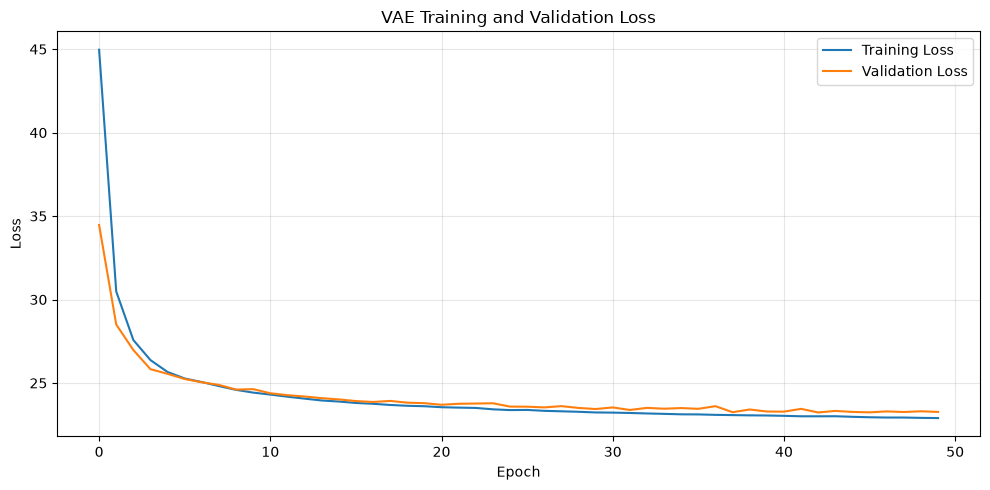

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("VAE Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vae_training_curves.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

In [14]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_mse_total = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        encoded = model.encoder(images)
        mu = model.fc_mu(encoded)
        reconstructed = model.decoder(mu)

        mse = nn.functional.mse_loss(
            reconstructed,
            images,
            reduction="sum"
        )

        test_mse_total += mse.item()

test_mse = test_mse_total / (len(test_dataset) * 784)

print(f"Best Checkpoint Epoch: {checkpoint['epoch']}")
print(f"Best Validation Loss: {checkpoint['val_loss']:.6f}")
print(f"VAE Test MSE: {test_mse:.6f}")

Best Checkpoint Epoch: 43
Best Validation Loss: 23.234563
VAE Test MSE: 0.016991


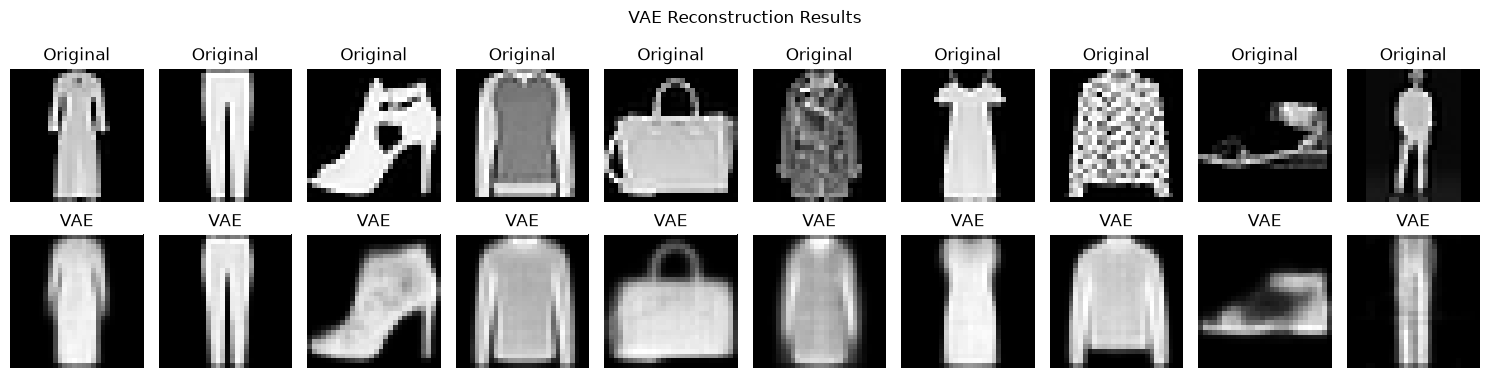

In [15]:
model.eval()

with torch.no_grad():
    images = X_test[:10].to(device)

    encoded = model.encoder(images)
    mu = model.fc_mu(encoded)
    reconstructed = model.decoder(mu)

original_images = images.cpu().view(-1, 1, 28, 28)
reconstructed_images = reconstructed.cpu().view(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):
    axes[0, i].imshow(original_images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[0, i].set_title("Original")

    axes[1, i].imshow(reconstructed_images[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")
    axes[1, i].set_title("VAE")

plt.suptitle("VAE Reconstruction Results")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vae_reconstructions.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

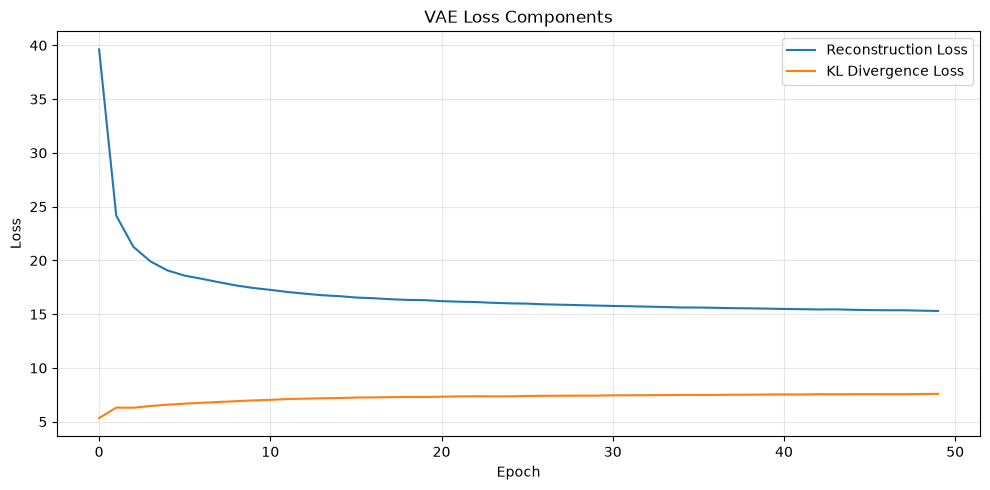

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(train_reconstruction_losses, label="Reconstruction Loss")
plt.plot(train_kl_losses, label="KL Divergence Loss")

plt.title("VAE Loss Components")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vae_loss_components.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

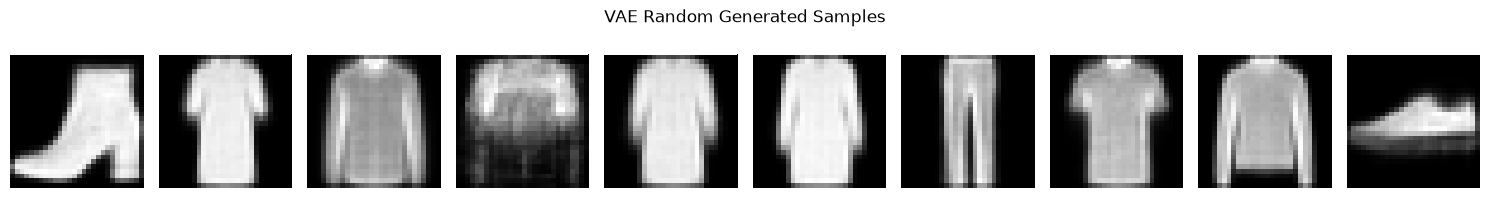

In [20]:
model.eval()

with torch.no_grad():
    z = torch.randn(10, VAE_CONFIG["latent_dim"]).to(device)
    generated_images = model.decoder(z)

generated_images = generated_images.cpu().view(-1, 1, 28, 28)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i in range(10):
    axes[i].imshow(generated_images[i].squeeze(), cmap="gray")
    axes[i].axis("off")

plt.suptitle("VAE Random Generated Samples")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vae_generated_samples.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()